# Costos y retorno de la inversión (ROI) del recomendador

**Autor:** Lookwise Data Lab
**Proyecto:** Sistema de recomendación para el e-commerce de H&M
**Notebook 08** · Usa los resultados del piloto A/B (notebook 07) · Detalle en `docs/costos_roi.md`

---

## Pregunta del cliente

H&M quiere saber **cuánto tiene que invertir** en el recomendador y **cuánto le va a retornar**, y si recupera la inversión en 6 meses.

## Criterios del análisis

| Pauta | Cómo se aplica |
|---|---|
| Costos técnicos con precios publicados de servicios | Nube con precios públicos de AWS; software de código abierto |
| Beneficio solo sobre el **canal online** | Se usa la facturación online de H&M (informe anual 2025), no la total |
| Incluir **honorarios profesionales** con tarifas norteamericanas, **separados** de lo técnico | USD 1.500 por científico de datos por mes durante 2 meses, con referencia a sueldos de EE. UU. de unos USD 160.000 al año |
| Simular con **datos sintéticos** | Monte Carlo: 10.000 escenarios posibles para los supuestos inciertos |

**Por qué simular:** H&M Argentina todavía no vende online, así que no hay facturación real. En lugar de apostar por un solo número, se sortean miles de combinaciones posibles de los supuestos y se mide **qué tan probable** es recuperar la inversión.

**Reproducibilidad:** no necesita los datos de `dataset/`. Todos los supuestos están en `src/roi.py` y la simulación usa semilla fija (42).

---
## Configuración

In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, os.path.abspath("../src"))
import roi

FIG_DIR, OUT_DIR = "../reports/figures", "../reports"
os.makedirs(FIG_DIR, exist_ok=True)
GRIS, VERDE, NARANJA, AZUL, TEXTO2 = "#9a9993", "#1baf7a", "#eb6834", "#2a78d6", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#d6d5cf",
    "axes.labelcolor": TEXTO2, "xtick.color": TEXTO2, "ytick.color": TEXTO2,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#ecebe6", "grid.linewidth": 0.8,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left", "legend.frameon": False,
})
pd.options.display.float_format = "{:,.0f}".format
def guardar(fig, nombre):
    fig.savefig(f"{FIG_DIR}/{nombre}.png", bbox_inches="tight", facecolor="white")
print("Supuestos cargados desde src/roi.py")

Supuestos cargados desde src/roi.py


---
# 1. Cuánto hay que invertir

**Qué hace:** separa los costos en **técnicos** (nube y software, con precios publicados) y **honorarios profesionales**.

**Supuestos:**
- **Nube:** 2 servidores para la API (respaldo si uno falla), 1 para reentrenar una vez por semana y 1 para MLflow y monitoreo, más un 20% de imprevistos.
- **Software:** USD 0, porque todo el sistema usa herramientas de código abierto (pandas, scikit-learn, MLflow, FastAPI, Streamlit).
- **Honorarios de desarrollo:** 5 científicos de datos durante 2 meses, a USD 1.500 por mes cada uno.
- **Operación:** después del lanzamiento, un científico de datos dedica el 25% de su tiempo a reentrenar y vigilar el modelo.
- **Plataforma de la tienda online:** se muestra **aparte**. La tienda online existe con o sin recomendador, así que no es un costo del recomendador; igual se incluye en un escenario de sensibilidad (sección 6).

In [2]:
costos = roi.tabla_costos()
desarrollo, mantenimiento = roi.honorarios()
tecnico = roi.costos_tecnicos_mensuales()
print(f"Inversión inicial (honorarios de desarrollo): USD {desarrollo:,.0f}")
print(f"Costo mensual de operación: USD {tecnico + mantenimiento:,.0f} "
      f"(técnico USD {tecnico:,.0f} + honorarios USD {mantenimiento:,.0f})")
print(f"Inversión total en 12 meses de operación: USD {desarrollo + 12 * (tecnico + mantenimiento):,.0f}")
costos

Inversión inicial (honorarios de desarrollo): USD 15,000
Costo mensual de operación: USD 650 (técnico USD 275 + honorarios USD 375)
Inversión total en 12 meses de operación: USD 22,805


,Tipo,Concepto,Única vez (USD),Por mes (USD)
0,Técnico (nube),API de recomendaciones (2 servidores m7i.large...,0,147
1,Técnico (nube),"Reentrenamiento semanal (m7i.xlarge, 10 h por ...",0,9
2,Técnico (nube),Seguimiento de experimentos (MLflow) y monitor...,0,74
3,Técnico (nube),Imprevistos (20%),0,46
4,Técnico (software),Licencias (todo es código abierto),0,0
5,Honorarios,Desarrollo: 5 científicos de datos × 2 meses,15000,0
6,Honorarios,Operación y reentrenamiento: 1 científico de d...,0,375
7,Referencia (aparte),Plataforma de la tienda online (tipo Shopify P...,0,2500


**Interpretación**
- La parte técnica es **barata** (unos USD 275 por mes): el modelo es liviano y se reentrena una vez por semana.
- Lo que más pesa son los **honorarios**: unos 86% de la inversión del primer año es el trabajo del equipo. Es el costo real de construir el sistema.

---
# 2. Cuánto puede facturar el canal online

**Qué hace:** estima la facturación online de un mercado de H&M con datos públicos del informe anual 2025.

**Cálculo:** ventas netas del grupo × parte online (algo más del 30%) ÷ 61 mercados online ÷ 12 meses = facturación online de un **mercado promedio** de H&M por mes.

**Argentina:** es un mercado nuevo, así que se supone que factura una **fracción** de un mercado promedio: entre 2% y 25%, con 10% como valor más probable. El mínimo (2%) equivale a la venta online asociada a una sola tienda de H&M (ventas por tienda × parte online), porque Argentina abre con una tienda. Además, el canal online arranca al 40% y llega a su nivel normal en 6 meses.

In [3]:
print(f"Facturación online de un mercado promedio de H&M: USD {roi.ONLINE_POR_MERCADO_MES:,.0f} por mes")
for nombre, t in zip(["mínimo", "más probable", "máximo"], roi.TAMANO_ARGENTINA):
    print(f"   Argentina, {nombre} ({t:.0%} de un mercado promedio): USD {roi.ONLINE_POR_MERCADO_MES * t:,.0f} por mes")

Facturación online de un mercado promedio de H&M: USD 9,730,180 por mes
   Argentina, mínimo (2% de un mercado promedio): USD 194,604 por mes
   Argentina, más probable (10% de un mercado promedio): USD 973,018 por mes
   Argentina, máximo (25% de un mercado promedio): USD 2,432,545 por mes


---
# 3. Cuánto retorna el recomendador

**Qué hace:** calcula la ganancia extra del recomendador como:

```
facturación online × venta extra por el recomendador × margen de contribución
```

| Supuesto | Mínimo | Más probable | Máximo | De dónde sale |
|---|---|---|---|---|
| Venta online extra | 1% | 3% | 6% | Parte de la mejora del piloto (+7,6 puntos en pedidos con prenda recomendada) que es venta nueva. Las encuestas de la industria esperan 6% o más de venta incremental por personalizar; se toma ese valor como máximo |
| Margen de contribución | 35% | 45% | 53,4% | Margen bruto de H&M en 2025 (53,4%) menos costos variables de la venta online (pago, envío) |

Primero se muestran tres escenarios fijos y después la simulación.

In [4]:
esc = roi.escenarios()
for _, r in esc.iterrows():
    rec = f"se recupera en el mes {int(r['Mes de recupero'])}" if pd.notna(r["Mes de recupero"]) else "no se recupera en 12 meses"
    print(f"{r['Escenario']:<10}: ROI a 12 meses {r['ROI a 12 meses (%)']:+.0f}% · {rec}")
esc

Pesimista : ROI a 12 meses -70% · no se recupera en 12 meses
Base      : ROI a 12 meses +488% · se recupera en el mes 3
Optimista : ROI a 12 meses +3386% · se recupera en el mes 1


,Escenario,Facturación online madura por mes (USD),Venta extra por el recomendador (%),Margen (%),Inversión total (USD),Beneficio total (USD),Resultado a 12 meses (USD),ROI a 6 meses (%),ROI a 12 meses (%),Mes de recupero
0,Pesimista,194604,1,35,22805,6947,-15857,-85,-70,NaN
1,Base,973018,3,45,22805,133985,111180,192,488,3
2,Optimista,2432545,6,53,22805,794975,772171,"1,632","3,386",1


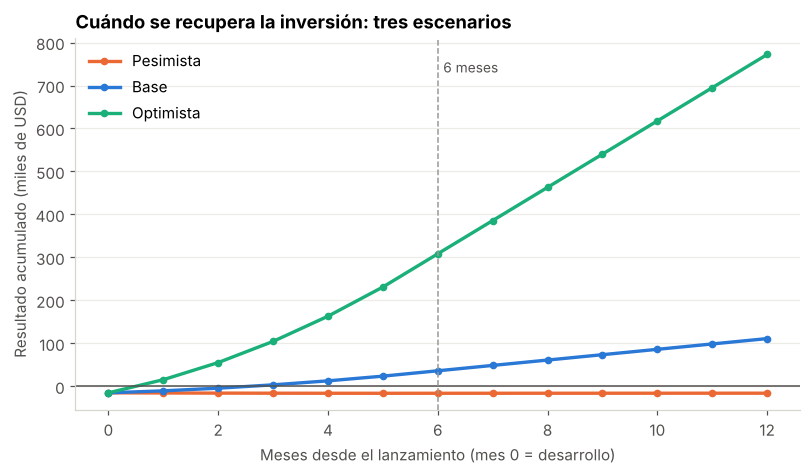

Por encima de la línea del 0, el recomendador ya pagó toda la inversión, incluidos los honorarios.


In [5]:
fig, ax = plt.subplots(figsize=(8.5, 4.4))
for i, (nombre, color) in enumerate(zip(["Pesimista", "Base", "Optimista"], [NARANJA, AZUL, VERDE])):
    f = roi.flujo(roi.TAMANO_ARGENTINA[i], roi.MEJORA_VENTAS[i], roi.MARGEN[i])
    ax.plot(f["Mes"], f["Acumulado (USD)"] / 1000, marker="o", ms=4, lw=2.2, color=color, label=nombre)
ax.axhline(0, color=TEXTO2, lw=1)
ax.axvline(6, color=GRIS, ls="--", lw=1)
ax.text(6.1, ax.get_ylim()[1] * 0.9, "6 meses", color=TEXTO2, fontsize=9)
ax.set_xlabel("Meses desde el lanzamiento (mes 0 = desarrollo)")
ax.set_ylabel("Resultado acumulado (miles de USD)")
ax.set_title("Cuándo se recupera la inversión: tres escenarios")
ax.legend(loc="upper left")
guardar(fig, "29_roi_escenarios")
plt.show()
print("Por encima de la línea del 0, el recomendador ya pagó toda la inversión, incluidos los honorarios.")

---
# 4. Simulación con datos sintéticos (Monte Carlo)

**Qué hace:** genera **10.000 escenarios sintéticos**. En cada uno sortea el tamaño del canal online de Argentina, la venta extra y el margen, cada uno entre su mínimo y su máximo (distribución triangular, con más peso en el valor más probable). Para cada escenario calcula el flujo mes a mes.

**Por qué:** en vez de una sola respuesta, da la **probabilidad** de recuperar la inversión. Es lo que necesita el cliente para decidir con el riesgo a la vista.

In [6]:
mc, acumulados = roi.montecarlo(n=10_000, semilla=42)
mes = mc["Mes de recupero"].fillna(99)
p6, p12 = (mes <= 6).mean(), (mes <= 12).mean()
q = mc["ROI a 12 meses (%)"].quantile([0.10, 0.50, 0.90])
print(f"Probabilidad de recuperar toda la inversión en 6 meses: {p6:.0%}")
print(f"Probabilidad de recuperarla en 12 meses: {p12:.0%}")
print(f"ROI a 12 meses: {q[0.5]:+.0f}% en el escenario mediano "
      f"(entre {q[0.1]:+.0f}% y {q[0.9]:+.0f}% en el 80% central de los escenarios).")
print(f"Mes de recupero mediano: {mes[mes < 99].median():.0f}")
resumen_mc = pd.DataFrame({
    "Indicador": ["Probabilidad de recuperar en 6 meses (%)", "Probabilidad de recuperar en 12 meses (%)",
                  "ROI a 12 meses, percentil 10 (%)", "ROI a 12 meses, mediana (%)", "ROI a 12 meses, percentil 90 (%)",
                  "Resultado a 12 meses, mediana (USD)", "Mes de recupero, mediana"],
    "Valor": [p6 * 100, p12 * 100, q[0.1], q[0.5], q[0.9], mc["Resultado a 12 meses (USD)"].median(), mes[mes < 99].median()]}).round(1)
resumen_mc

Probabilidad de recuperar toda la inversión en 6 meses: 98%
Probabilidad de recuperarla en 12 meses: 100%
ROI a 12 meses: +621% en el escenario mediano (entre +231% y +1266% en el 80% central de los escenarios).
Mes de recupero mediano: 3


,Indicador,Valor
0,Probabilidad de recuperar en 6 meses (%),98
1,Probabilidad de recuperar en 12 meses (%),100
2,"ROI a 12 meses, percentil 10 (%)",231
3,"ROI a 12 meses, mediana (%)",621
4,"ROI a 12 meses, percentil 90 (%)","1,266"
5,"Resultado a 12 meses, mediana (USD)","141,586"
6,"Mes de recupero, mediana",3


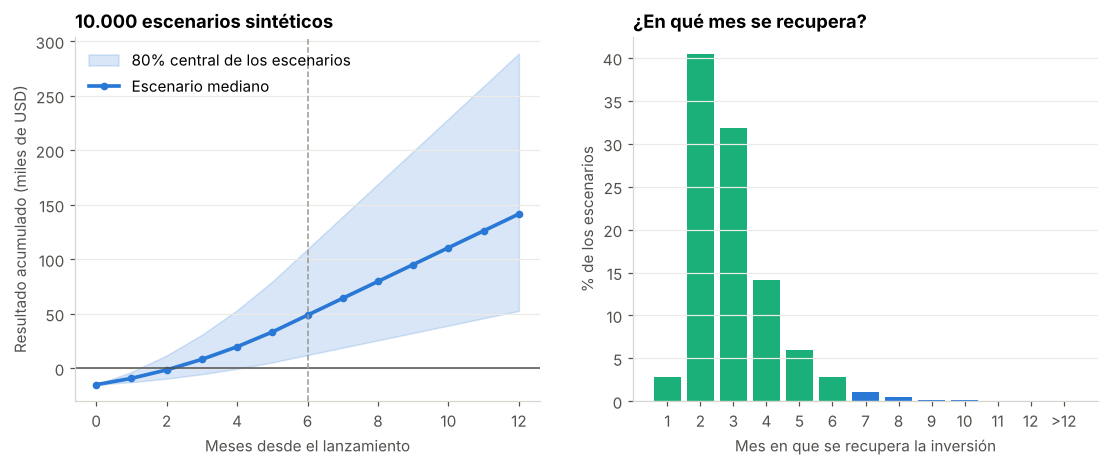

Verde: se recupera en 6 meses o menos · Azul: entre 7 y 12 meses · Gris: tarda más de 12 meses.


In [7]:
p10, p50, p90 = np.percentile(acumulados, [10, 50, 90], axis=0) / 1000
meses = np.arange(acumulados.shape[1])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
ax = axes[0]
ax.fill_between(meses, p10, p90, color=AZUL, alpha=0.18, label="80% central de los escenarios")
ax.plot(meses, p50, color=AZUL, lw=2.4, marker="o", ms=4, label="Escenario mediano")
ax.axhline(0, color=TEXTO2, lw=1); ax.axvline(6, color=GRIS, ls="--", lw=1)
ax.set_xlabel("Meses desde el lanzamiento"); ax.set_ylabel("Resultado acumulado (miles de USD)")
ax.set_title("10.000 escenarios sintéticos"); ax.legend(loc="upper left")
ax = axes[1]
conteo = mes.clip(upper=13).value_counts().sort_index()
colores = [VERDE if m <= 6 else (AZUL if m <= 12 else GRIS) for m in conteo.index]
ax.bar([str(int(m)) if m <= 12 else ">12" for m in conteo.index], conteo.values / len(mes) * 100, color=colores)
ax.set_xlabel("Mes en que se recupera la inversión"); ax.set_ylabel("% de los escenarios")
ax.set_title("¿En qué mes se recupera?")
guardar(fig, "30_roi_montecarlo")
plt.show()
print("Verde: se recupera en 6 meses o menos · Azul: entre 7 y 12 meses · Gris: tarda más de 12 meses.")

### ¿Qué supuesto pesa más?

**Qué hace:** compara el resultado a 12 meses de los escenarios según cada supuesto, para ver cuál conviene medir mejor.

In [8]:
sens = []
for col, nombre in [("tamano", "Tamaño del canal online"), ("mejora", "Venta extra por el recomendador"), ("margen", "Margen de contribución")]:
    bajo = mc[mc[col] <= mc[col].quantile(0.25)]["Resultado a 12 meses (USD)"].median()
    alto = mc[mc[col] >= mc[col].quantile(0.75)]["Resultado a 12 meses (USD)"].median()
    sens.append({"Supuesto": nombre, "Resultado mediano si es bajo (USD)": bajo, "Resultado mediano si es alto (USD)": alto,
                 "Diferencia (USD)": alto - bajo})
sens = pd.DataFrame(sens).sort_values("Diferencia (USD)", ascending=False)
print(f"El supuesto que más mueve el resultado es: {sens.iloc[0]['Supuesto']}.")
sens

El supuesto que más mueve el resultado es: Tamaño del canal online.


,Supuesto,Resultado mediano si es bajo (USD),Resultado mediano si es alto (USD),Diferencia (USD)
0,Tamaño del canal online,"68,408","247,085","178,677"
1,Venta extra por el recomendador,"81,182","219,228","138,046"
2,Margen de contribución,"124,112","161,129","37,018"


---
# 5. Punto de equilibrio

**Qué hace:** calcula dos puntos de equilibrio con los supuestos más probables (3% de venta extra y 45% de margen):

- **Operativo:** la facturación online mensual a partir de la cual lo que gana el recomendador en un mes cubre lo que cuesta operarlo ese mes (USD 650).
- **De recupero:** la facturación online mensual necesaria para recuperar además los USD 15.000 del desarrollo en 6 o en 12 meses.

Los tres escenarios de la sección 3 se leen a partir de estos puntos: el pesimista queda cerca del equilibrio, el base y el optimista muy por encima.

In [9]:
pe_op = roi.punto_equilibrio_operativo()
print(f"Equilibrio operativo: USD {pe_op:,.0f} de facturación online por mes "
      f"({pe_op / roi.ONLINE_POR_MERCADO_MES:.1%} de un mercado online promedio de H&M).")
pe = pd.DataFrame([{"Plazo para recuperar": f"{m} meses", "Facturación online necesaria por mes (USD)": roi.punto_equilibrio(m),
                    "Como % de un mercado online promedio de H&M": roi.punto_equilibrio(m) / roi.ONLINE_POR_MERCADO_MES * 100}
                   for m in [6, 12]])
print(f"Para recuperar en 6 meses, el canal online de Argentina tiene que facturar unos USD {pe.iloc[0, 1]:,.0f} por mes, "
      f"el {pe.iloc[0, 2]:.0f}% de un mercado online promedio de H&M.")
pe

Equilibrio operativo: USD 48,177 de facturación online por mes (0.5% de un mercado online promedio de H&M).
Para recuperar en 6 meses, el canal online de Argentina tiene que facturar unos USD 233,362 por mes, el 2% de un mercado online promedio de H&M.


,Plazo para recuperar,Facturación online necesaria por mes (USD),Como % de un mercado online promedio de H&M
0,6 meses,"233,362",2
1,12 meses,"140,769",1


---
# 6. Sensibilidad: ¿y si se suma la plataforma online?

**Qué hace:** repite los escenarios sumando el costo de una tienda online tipo Shopify Plus (USD 2.500 por mes). Es un escenario conservador: la tienda online existe con o sin recomendador.

In [10]:
esc_p = roi.escenarios(con_plataforma=True)
mc_p, _ = roi.montecarlo(n=10_000, semilla=42, con_plataforma=True)
mes_p = mc_p["Mes de recupero"].fillna(99)
print(f"Sumando la plataforma: probabilidad de recuperar en 6 meses {(mes_p <= 6).mean():.0%} "
      f"y en 12 meses {(mes_p <= 12).mean():.0%}.")
esc_p

Sumando la plataforma: probabilidad de recuperar en 6 meses 87% y en 12 meses 96%.


,Escenario,Facturación online madura por mes (USD),Venta extra por el recomendador (%),Margen (%),Inversión total (USD),Beneficio total (USD),Resultado a 12 meses (USD),ROI a 6 meses (%),ROI a 12 meses (%),Mes de recupero
0,Pesimista,194604,1,35,52805,6947,-45857,-92,-87,NaN
1,Base,973018,3,45,52805,133985,81180,63,154,4
2,Optimista,2432545,6,53,52805,794975,742171,866,"1,406",1


---
# 7. Conclusiones para el cliente

- **Cuánto invertir:** **USD 15.000** de honorarios para construir el sistema (5 científicos de datos durante 2 meses) y unos **USD 650 por mes** para operarlo (USD 275 de nube y USD 375 de un científico de datos a tiempo parcial). El software no tiene costo de licencias. En total, unos **USD 22.800** en el primer año.
- **Cuánto retorna:** depende sobre todo del **tamaño del canal online** en Argentina. En el escenario más probable, el recomendador se paga en el **mes 3** y termina el primer año con ganancia; los números de la simulación están en la sección 4.
- **El riesgo:** en el escenario pesimista (un canal online del tamaño de una sola tienda y poca venta extra) la inversión no se recupera en el primer año. Por eso el **piloto A/B** del plan de validación es clave: mide la venta extra real antes de escalar y permite recalcular este ROI con datos de H&M Argentina.

### Limitaciones
- La facturación de Argentina se estima con el promedio de los mercados online de H&M; el valor real dependerá del lanzamiento.
- La venta extra sale de una simulación con datos históricos de otro mercado; el piloto A/B es la forma de medirla.
- Los precios de nube son on-demand; con contratos de 1 a 3 años bajan entre 27% y 49%.
- No se descuenta el valor del dinero en el tiempo, porque el horizonte es de solo 12 meses.

---
# 8. Exportar resultados
**Qué hace:** guarda las tablas en `reports/` para el dashboard y la presentación. `roi_flujos_powerbi.csv` tiene el flujo mes a mes de cada escenario, con y sin plataforma, en formato largo para filtrar por escenario en Power BI.

In [11]:
costos.to_csv(f"{OUT_DIR}/roi_costos.csv", index=False, encoding="utf-8-sig")
esc.to_csv(f"{OUT_DIR}/roi_escenarios.csv", index=False, encoding="utf-8-sig")
resumen_mc.to_csv(f"{OUT_DIR}/roi_montecarlo_resumen.csv", index=False, encoding="utf-8-sig")
roi.flujo(roi.TAMANO_ARGENTINA[1], roi.MEJORA_VENTAS[1], roi.MARGEN[1]).to_csv(f"{OUT_DIR}/roi_flujo_base.csv", index=False, encoding="utf-8-sig")
pd.concat([roi.flujos_powerbi(), roi.flujos_powerbi(con_plataforma=True)]).to_csv(f"{OUT_DIR}/roi_flujos_powerbi.csv", index=False, encoding="utf-8-sig")
print("Guardados roi_costos.csv, roi_escenarios.csv, roi_montecarlo_resumen.csv, roi_flujo_base.csv y roi_flujos_powerbi.csv en reports/")

Guardados roi_costos.csv, roi_escenarios.csv, roi_montecarlo_resumen.csv, roi_flujo_base.csv y roi_flujos_powerbi.csv en reports/
